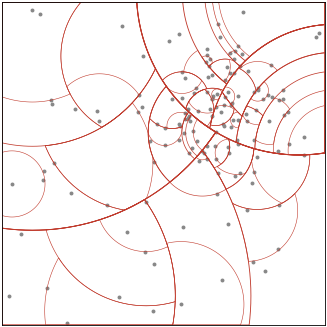

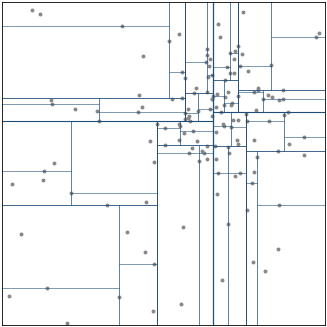

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from shapely.geometry import Polygon

# ---------- publication style ----------
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.linewidth': 0.6,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.02,
})

COL_VP = '#c0392b'   # muted brick red
COL_KD = '#1f4e79'   # dark slate blue
COL_PT = '#888888'

# ---------- kd-tree ----------
def build_kdtree(points, depth, bounds, segments, max_depth):
    if len(points) <= 1 or depth >= max_depth:
        return
    axis = depth % 2
    order = np.argsort(points[:, axis])
    mid = len(points) // 2
    val = points[order[mid], axis]
    xmin, xmax, ymin, ymax = bounds
    if axis == 0:
        segments.append((depth, np.array([(val, ymin), (val, ymax)])))   # <-- np.array
        lb, rb = [xmin, val, ymin, ymax], [val, xmax, ymin, ymax]
    else:
        segments.append((depth, np.array([(xmin, val), (xmax, val)])))   # <-- np.array
        lb, rb = [xmin, xmax, ymin, val], [xmin, xmax, val, ymax]
    build_kdtree(points[order[:mid]], depth+1, lb, segments, max_depth)
    build_kdtree(points[order[mid:]], depth+1, rb, segments, max_depth)

# ---------- vp-tree (nested) ----------
def circle_poly(c, r, n=200):
    th = np.linspace(0, 2*np.pi, n, endpoint=False)
    return Polygon(np.column_stack([c[0]+r*np.cos(th), c[1]+r*np.sin(th)]))

def build_vptree(points, region, depth, segments, max_depth):
# DISCLAIMER: This toy vptree implementation was produced by DeepSeek LLM,
#               it is NOT the VP-tree_MS_0_inf described in the paper
    if len(points) <= 1 or depth >= max_depth:
        return
    cen = np.array(region.centroid.coords[0])
    vp = points[np.argmax(np.linalg.norm(points - cen, axis=1))]
    d = np.linalg.norm(points - vp, axis=1)
    r = np.median(d)
    disc = circle_poly(vp, r)
    cut = region.intersection(disc)
    for ring in _rings(cut):
        segments.append((depth, np.array(ring.coords)))
    cin = region.intersection(disc)
    cout = region.difference(disc)
    if cin.is_empty or cout.is_empty:
        return
    m = d <= r
    build_vptree(points[m],  cin,  depth+1, segments, max_depth)
    build_vptree(points[~m], cout, depth+1, segments, max_depth)

def _rings(geom):
    if geom.is_empty: return
    polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
    for p in polys:
        yield p.exterior
        for h in p.interiors:
            yield h

# ---------- data ----------
rng = np.random.default_rng(42)
pts = rng.random((50, 2))

pts = np.concat([pts, rng.normal(loc=0.6, scale=0.4, size=(100, 2))*0.3 + 0.5])

kd_seg, vp_seg = [], []
build_kdtree(pts, 0, [0, 1, 0, 1], kd_seg, max_depth=6)
build_vptree(pts, Polygon([(0,0),(1,0),(1,1),(0,1)]), 0, vp_seg, max_depth=6)

# ---------- plot ----------
def draw(ax, segs, colour, is_arc=False):
    ax.scatter(pts[:,0], pts[:,1], s=8, c=COL_PT, alpha=1.0, linewidths=0)
    for depth, seg in segs:
        seg = np.asarray(seg)                                            # <-- universal coercion
        lw = (0.9 if not is_arc else 0.8) * (1.0 - 0.55 * depth / 5)
        ax.plot(seg[:, 0], seg[:, 1], color=colour, lw=max(lw, 0.4),
                solid_capstyle='round')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])

edge_size = 3.5
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(edge_size,edge_size))
draw(ax, vp_seg, COL_VP, is_arc=True)
plt.tight_layout()
plt.savefig(f'./results/synthetic/vptree.eps', format = 'eps', bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(edge_size,edge_size))
draw(ax, kd_seg, COL_KD)
plt.tight_layout()
plt.savefig(f'./results/synthetic/kdtree.eps', format = 'eps', bbox_inches='tight')
plt.show()